# Clustering – Typologie du risque d'inondation (Casablanca-Settat, mailles 100 m)
Suit le diagramme de classes : `ModeleClustering` (abstraite) → `KMeans` (baseline), `GMM` (modèle), `AffectationCluster`, `ClusterTypologie`.

**Protocole ML**
1. Jeu d'entraînement / test (découpage spatial par blocs si les coordonnées existent, sinon aléatoire).
2. Choix de k : on teste k = 2…10, on trace les graphes, puis on retient le k convenable.
3. Entraînement de K-Means (baseline) et GMM (modèle) sur le jeu d'entraînement.
4. Évaluation **sur le jeu de test** : silhouette, Davies-Bouldin, Calinski-Harabasz, puis précision / rappel / F1 / matrice de confusion et RMSE en utilisant la classe AHP (1-5) comme référence.
5. Comparaison avec la baseline et une référence naïve, documentation des choix et des limites.

In [5]:
from datetime import datetime
from pathlib import Path
from abc import ABC, abstractmethod
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans as SKKMeans
from sklearn.mixture import GaussianMixture as SKGMM
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, mean_squared_error)

# --- Racine du projet (même logique que le notebook AHP)
ROOT = Path.cwd()
if ROOT.name == "scripts":
    ROOT = ROOT.parent

DOSSIER_AHP = ROOT / "donnees_traitees" / "ahp"          # entrées
OUT = ROOT / "donnees_traitees" / "clustering"           # sorties
OUT.mkdir(parents=True, exist_ok=True)

CSV_MAILLES = ROOT / "donnees_traitees" / "mailles" / "mailles_100m_normalisees.csv"
CSV_CRITERE = DOSSIER_AHP / "critere_ahp.csv"
CSV_SCORE   = DOSSIER_AHP / "score_risque.csv"

CALCUL_ID = 1
SEED = 42
K_RANGE = range(2, 11)     # valeurs de k testées
K_MANUEL = None            # ex. 4 pour forcer k (sinon choix automatique après les graphes)
TEST_FRAC = 0.20           # part de test
BLOC_M = 5000              # taille des blocs spatiaux (m) pour le découpage
N_RECHERCHE_K = 100_000    # mailles d'entraînement utilisées pour la recherche de k
N_EVAL = 20_000            # échantillon de test pour silhouette / CH (coûteuses)

# Même convention que le notebook AHP : les variables « cost » sont inversées (1 - x) ici.
# Mettre False si l'inversion est déjà faite dans mailles_100m_normalisees.csv (évite la double inversion).
APPLIQUER_SENS = True

## 1. Classes du diagramme

In [6]:
def metriques_internes(X, g, n=N_EVAL):
    """Silhouette (échantillon), Davies-Bouldin, Calinski-Harabasz."""
    if len(np.unique(g)) < 2:
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    rng = np.random.default_rng(SEED)
    idx = rng.choice(len(X), min(len(X), n), replace=False)
    sil = silhouette_score(X[idx], g[idx]) if len(np.unique(g[idx])) > 1 else np.nan
    return {"silhouette": float(sil), "davies_bouldin": float(davies_bouldin_score(X, g)),
            "calinski_harabasz": float(calinski_harabasz_score(X, g))}


class ModeleClustering(ABC):
    """Classe abstraite : id, calcul_id, role, n_clusters, date_entrainement, silhouette, davies_bouldin."""
    def __init__(self, id, calcul_id, role, n_clusters):
        self.id, self.calcul_id, self.role, self.n_clusters = id, calcul_id, role, n_clusters
        self.date_entrainement = None
        self.silhouette = None
        self.davies_bouldin = None
        self.calinski_harabasz = None
        self.modele = None

    @abstractmethod
    def entrainer(self, X): ...

    @abstractmethod
    def predire(self, X):
        """Retourne (groupe, probabilite) pour chaque maille."""

    def evaluer(self, X, groupes):
        """Évaluation sur le jeu passé en argument (ici : le jeu de TEST)."""
        m = metriques_internes(X, groupes)
        self.silhouette, self.davies_bouldin = m["silhouette"], m["davies_bouldin"]
        self.calinski_harabasz = m["calinski_harabasz"]

    def vers_ligne(self):
        return {"id": self.id, "calcul_id": self.calcul_id, "role": self.role,
                "type": type(self).__name__, "n_clusters": self.n_clusters,
                "date_entrainement": self.date_entrainement,
                "silhouette": self.silhouette, "davies_bouldin": self.davies_bouldin,
                "calinski_harabasz": self.calinski_harabasz}


class KMeans(ModeleClustering):
    def __init__(self, id, calcul_id, n_clusters):
        super().__init__(id, calcul_id, "baseline", n_clusters)
        self.inertie = None

    def entrainer(self, X):
        self.modele = SKKMeans(n_clusters=self.n_clusters, n_init=10, random_state=SEED).fit(X)
        self.inertie = float(self.modele.inertia_)
        self.date_entrainement = datetime.now().isoformat(timespec="seconds")

    def predire(self, X):
        return self.modele.predict(X), np.ones(len(X))      # K-Means : probabilite = 1

    def vers_ligne(self):
        return {**super().vers_ligne(), "inertie": self.inertie}


class GMM(ModeleClustering):
    def __init__(self, id, calcul_id, n_clusters, covariance="full"):
        super().__init__(id, calcul_id, "modele", n_clusters)
        self.covariance = covariance
        self.bic = None
        self.loglik_test = None

    def entrainer(self, X):
        self.modele = SKGMM(n_components=self.n_clusters, covariance_type=self.covariance,
                    reg_covar=1e-4, n_init=3, random_state=SEED).fit(X)
        self.bic = float(self.modele.bic(X))                 # BIC sur le jeu d'entraînement
        self.date_entrainement = datetime.now().isoformat(timespec="seconds")

    def predire(self, X):
        P = self.modele.predict_proba(X)
        return P.argmax(axis=1), P.max(axis=1)               # groupe le plus probable + sa probabilité

    def evaluer(self, X, groupes):
        super().evaluer(X, groupes)
        self.loglik_test = float(self.modele.score(X))       # log-vraisemblance moyenne sur le test

    def vers_ligne(self):
        return {**super().vers_ligne(), "covariance": self.covariance, "bic": self.bic,
                "loglik_test": self.loglik_test}

## 2. Entrées et découpage entraînement / test

In [7]:
import sqlite3
import pandas as pd
import numpy as np
from pathlib import Path

# === Chemins ===
ROOT = Path.cwd()
if ROOT.name == "scripts":
    ROOT = ROOT.parent

DOSSIER_AHP = ROOT / "donnees_traitees" / "ahp"
OUT = ROOT / "donnees_traitees" / "clustering"
OUT.mkdir(parents=True, exist_ok=True)

CSV_MAILLES = ROOT / "donnees_traitees" / "mailles" / "mailles_100m_normalisees.csv"
CSV_CRITERE = DOSSIER_AHP / "critere_ahp.csv"
CSV_SCORE   = DOSSIER_AHP / "score_risque.csv"
FICHIER_GPKG = ROOT / "donnees_traitees" / "mailles" / "mailles_100m.gpkg"

CALCUL_ID = 1
SEED = 42
TEST_FRAC = 0.20
BLOC_M = 5000          # taille des blocs spatiaux en mètres

# === 1. Chargement des données tabulaires ===
df = pd.read_csv(CSV_MAILLES)
critere = pd.read_csv(CSV_CRITERE).query("calcul_id == @CALCUL_ID")
score = pd.read_csv(CSV_SCORE).query("calcul_id == @CALCUL_ID").set_index("maille_id")

# === 2. Récupération des coordonnées depuis le GeoPackage ===
# Dans la table 'mailles_100m', l'identifiant s'appelle 'maille_id' (pas 'id')
with sqlite3.connect(FICHIER_GPKG) as conn:
    df_xy = pd.read_sql_query(
        """
        SELECT maille_id AS id,
               centroide_x,
               centroide_y
        FROM "mailles_100m"
        """,
        conn
    )

# Fusion sur 'id' (qui existe déjà dans le CSV normalisé)
df = df.merge(df_xy, on="id", how="left")

# Vérification
if df["centroide_x"].isna().any() or df["centroide_y"].isna().any():
    n_missing = df["centroide_x"].isna().sum()
    raise ValueError(f"{n_missing} mailles sans coordonnées après fusion. Vérifiez la correspondance id ↔ maille_id.")

print(f"[OK] Coordonnées fusionnées : {len(df):,} mailles")
print(f"     centroide_x : [{df['centroide_x'].min():.1f} → {df['centroide_x'].max():.1f}]")
print(f"     centroide_y : [{df['centroide_y'].min():.1f} → {df['centroide_y'].max():.1f}]")

# === 3. Préparation des variables (comme avant) ===
criteres = critere["variable"].tolist()
poids = critere.set_index("variable")["poids"]
sens  = critere.set_index("variable")["sens"]

V = df[criteres].astype("float32").copy()

# Appliquer le sens (cost → inversion) si nécessaire
if APPLIQUER_SENS:           # défini dans la cellule de configuration
    for c in criteres:
        if sens[c] == "cost":
            V[c] = 1 - V[c]

# Garder uniquement les mailles complètes
masque = V.notna().all(axis=1).to_numpy()
V = V[masque].reset_index(drop=True)
sub = df.loc[masque].reset_index(drop=True)
maille_id = sub["id"]

valeur = maille_id.map(score["valeur"])
classe = maille_id.map(score["classe"])

# Vérifications : pas de NaN, et sens de la classe (classe AHP 5 = très élevé => corrélation positive attendue)
print("NaN valeur/classe :", valeur.isna().sum(), classe.isna().sum(),
      "| Spearman(valeur, classe) =", round(valeur.corr(classe, method="spearman"), 3))

X = (V.to_numpy() * np.sqrt(poids[criteres].to_numpy(dtype="float32"))).astype("float32")

# === 4. Découpage spatial par blocs (maintenant possible) ===
rng = np.random.default_rng(SEED)

# On utilise maintenant les vraies coordonnées
bloc = (
    (sub["centroide_x"] // BLOC_M).astype(int) * 1_000_000
    + (sub["centroide_y"] // BLOC_M).astype(int)
)

blocs = bloc.unique()
n_blocs_test = max(1, int(len(blocs) * TEST_FRAC))
blocs_test = rng.choice(blocs, size=n_blocs_test, replace=False)
est_test = bloc.isin(blocs_test).to_numpy()

mode_split = f"spatial (blocs de {BLOC_M} m)"

X_train, X_test = X[~est_test], X[est_test]
classe_train, classe_test = classe[~est_test].to_numpy(), classe[est_test].to_numpy()
valeur_train, valeur_test = valeur[~est_test].to_numpy(), valeur[est_test].to_numpy()

print(f"\nDécoupage {mode_split}")
print(f"Train = {len(X_train):,}  |  Test = {len(X_test):,}  ({len(X_test)/len(X):.1%})")
print(f"Nombre de blocs totaux : {len(blocs)}  →  blocs test : {n_blocs_test}")

[OK] Coordonnées fusionnées : 2,020,705 mailles
     centroide_x : [157050.0 → 373350.0]
     centroide_y : [192950.0 → 360550.0]
NaN valeur/classe : 0 0 | Spearman(valeur, classe) = 0.751

Découpage spatial (blocs de 5000 m)
Train = 1,597,429  |  Test = 423,276  (20.9%)
Nombre de blocs totaux : 905  →  blocs test : 181


### Contrôle du sens des critères (`hand_moy`, `distance_oued`, `pente_moy`)

In [8]:
# Vérification du sens des critères (hand_moy, distance_oued, pente_moy attendus « cost »)
CRIT_COST_ATTENDUS = ["distance_oued"]   # hand_moy et pente_moy sont déjà inversés dans le CSV normalisé
ech = np.random.default_rng(SEED).choice(len(V), min(len(V), 200_000), replace=False)

tab_sens = pd.DataFrame({"poids": poids[criteres], "sens": sens[criteres]})
tab_sens["attendu_cost"] = tab_sens.index.isin(CRIT_COST_ATTENDUS)
tab_sens["inverse_ici"] = [APPLIQUER_SENS and sens[c] == "cost" for c in criteres]
# V est déjà orienté : après inversion, Spearman(variable, score) doit être > 0 pour toutes
tab_sens["spearman_vs_score"] = [V[c].iloc[ech].corr(valeur.iloc[ech], method="spearman") for c in criteres]
tab_sens["alerte"] = (tab_sens["spearman_vs_score"] < 0) | (tab_sens["attendu_cost"] & (tab_sens["sens"] != "cost"))
tab_sens.round(3)

,poids,sens,attendu_cost,inverse_ici,spearman_vs_score,alerte
variable,,,,,,
hand_moy,0.219,benefit,False,False,0.630,False
flux_max_log,0.129,benefit,False,False,0.618,False
twi_moy,0.129,benefit,False,False,0.746,False
pct_impermeable,0.042,benefit,False,False,0.095,False
distance_oued,0.129,cost,True,True,0.510,False
depression_moy,0.072,benefit,False,False,0.541,False
ruissel_moy,0.072,benefit,False,False,0.326,False
pente_moy,0.042,benefit,False,False,0.554,False
densite_bati,0.071,benefit,False,False,0.048,False


In [9]:
D = df.loc[masque, ["hand_moy", "pente_moy", "twi_moy", "distance_oued"]].iloc[ech]
print(D.corr(method="spearman").round(2))

               hand_moy  pente_moy  twi_moy  distance_oued
hand_moy           1.00       0.64     0.64          -0.04
pente_moy          0.64       1.00     0.75          -0.07
twi_moy            0.64       0.75     1.00          -0.07
distance_oued     -0.04      -0.07    -0.07           1.00


## 3. Choix de k : validation croisée spatiale dans le train (le test n'est pas utilisé)
Critères propres au GMM : ICL/BIC, log-vraisemblance en validation spatiale, stabilité (ARI), taille minimale des clusters, η² du score AHP.

In [10]:
from sklearn.model_selection import GroupKFold
from collections import Counter

K_CAND     = [k for k in K_RANGE if 3 <= k <= 8]   # nb de types exploitable pour prioriser
N_FOLDS    = 3          # validation croisée spatiale (par blocs) DANS le train
N_FIT      = 30_000     # mailles par ajustement GMM
STAB_MIN   = 0.70       # ARI minimal entre 2 ajustements indépendants
TAILLE_MIN = 0.01       # le plus petit cluster doit contenir >= 1 % des mailles

bloc_train = bloc[~est_test].to_numpy()
folds = list(GroupKFold(n_splits=N_FOLDS).split(X_train, groups=bloc_train))
rng = np.random.default_rng(SEED)

def eta2(y, g):
    """Part de variance du score AHP expliquée par les clusters."""
    y = np.asarray(y, float); g = np.asarray(g)
    ssw = sum(((y[g == c] - y[g == c].mean()) ** 2).sum() for c in np.unique(g))
    return 1 - ssw / ((y - y.mean()) ** 2).sum()

lignes = []
for k in K_RANGE:
    for itr, iva in folds:
        ia = rng.choice(itr, min(len(itr), N_FIT), replace=False)
        ib = rng.choice(itr, min(len(itr), N_FIT), replace=False)
        Xa, Xv = X_train[ia], X_train[iva]
        gm = SKGMM(k, covariance_type="full", reg_covar=1e-4, n_init=1, random_state=SEED).fit(Xa)
        gb = SKGMM(k, covariance_type="full", reg_covar=1e-4, n_init=1, random_state=SEED + 1).fit(X_train[ib])
        km = SKKMeans(k, n_init=3, random_state=SEED).fit(Xa)
        Pa, gv = gm.predict_proba(Xa), gm.predict(Xv)
        entropie = float(-(Pa * np.log(Pa + 1e-12)).sum(axis=1).mean())
        mg = metriques_internes(Xv, gv, n=5000)
        mk = metriques_internes(Xv, km.predict(Xv), n=5000)
        lignes.append({"k": k, "bic": gm.bic(Xa), "icl": gm.bic(Xa) + 2 * len(Xa) * entropie,
                       "loglik_val": gm.score(Xv),
                       "stabilite_ari": adjusted_rand_score(gv, gb.predict(Xv)),
                       "taille_min": np.bincount(gv, minlength=k).min() / len(gv),
                       "eta2_ahp": eta2(valeur_train[iva], gv),
                       "sil_gmm": mg["silhouette"], "db_gmm": mg["davies_bouldin"],
                       "sil_kmeans": mk["silhouette"], "db_kmeans": mk["davies_bouldin"]})
val_k = pd.DataFrame(lignes).groupby("k").mean()
val_k.round(4)

c:\Users\dell\.conda\envs\pycaret-env\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\dell\.conda\envs\pycaret-env\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\dell\.conda\envs\pycaret-env\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\dell\.conda\envs\pycaret-env\lib\subprocess.py", line 971, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\dell\.conda\envs\pycaret-env\lib\subprocess.py", line 1456, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess

,bic,icl,loglik_val,stabilite_ari,taille_min,eta2_ahp,sil_gmm,db_gmm,sil_kmeans,db_kmeans
k,,,,,,,,,,
2,-1.874598e+06,-1.872829e+06,31.2210,0.9575,0.1006,0.1651,0.2218,2.0472,0.2611,1.4561
3,-1.932659e+06,-1.924900e+06,32.2112,0.5685,0.0636,0.3801,0.1882,2.0513,0.2689,1.3345
4,-1.954067e+06,-1.941240e+06,32.6067,0.8559,0.0242,0.4596,0.1581,1.6696,0.2410,1.3034
5,-1.968585e+06,-1.951566e+06,32.8481,0.8607,0.0242,0.5500,0.1765,1.4819,0.2323,1.3104
6,-1.972496e+06,-1.951508e+06,32.9201,0.8145,0.0241,0.6331,0.1629,1.5331,0.2224,1.3198
7,-1.976714e+06,-1.954339e+06,33.0036,0.4504,0.0159,0.6522,0.1530,1.6138,0.2197,1.2715
8,-1.984300e+06,-1.959398e+06,33.1117,0.5158,0.0241,0.6769,0.1477,1.5874,0.2231,1.2808
9,-1.984871e+06,-1.959530e+06,33.1475,0.4932,0.0241,0.6963,0.1373,1.7174,0.2211,1.2645
10,-1.989484e+06,-1.964185e+06,33.2667,0.4261,0.0230,0.6625,0.1165,1.6990,0.2232,1.2091


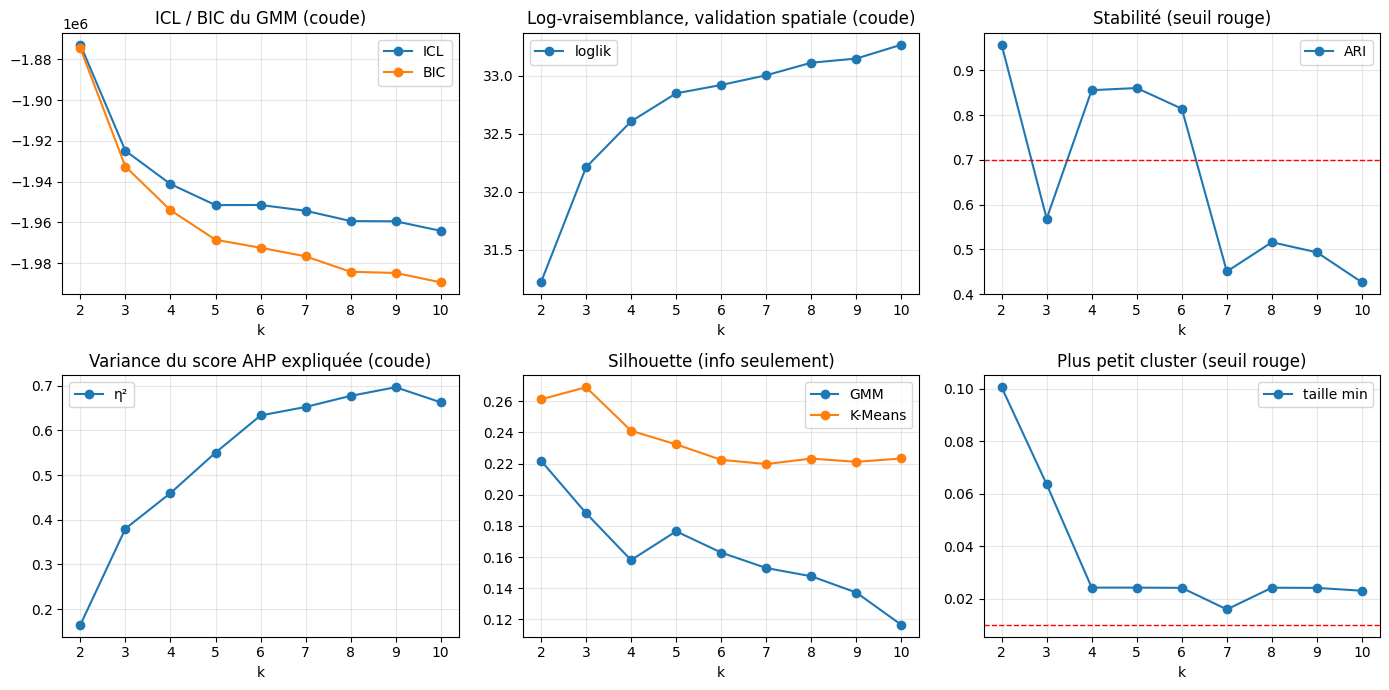

k admissibles : [4, 5, 6] 
Votes : {'coude_icl': 5, 'coude_loglik_val': 5, 'coude_eta2_ahp': 5}
k automatique = 5 | ARI = 0.861 (seuil 0.7) | origine : automatique => k retenu = 5


In [11]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7)); ks = val_k.index
def tracer(a, cols, titre, ligne=None):
    for c, lab in cols: a.plot(ks, val_k[c], "o-", label=lab)
    if ligne is not None: a.axhline(ligne, color="r", ls="--", lw=1)
    a.set_title(titre); a.set_xlabel("k"); a.grid(alpha=.3); a.legend()
tracer(ax[0, 0], [("icl", "ICL"), ("bic", "BIC")], "ICL / BIC du GMM (coude)")
tracer(ax[0, 1], [("loglik_val", "loglik")], "Log-vraisemblance, validation spatiale (coude)")
tracer(ax[0, 2], [("stabilite_ari", "ARI")], "Stabilité (seuil rouge)", STAB_MIN)
tracer(ax[1, 0], [("eta2_ahp", "η²")], "Variance du score AHP expliquée (coude)")
tracer(ax[1, 1], [("sil_gmm", "GMM"), ("sil_kmeans", "K-Means")], "Silhouette (info seulement)")
tracer(ax[1, 2], [("taille_min", "taille min")], "Plus petit cluster (seuil rouge)", TAILLE_MIN)
plt.tight_layout(); plt.savefig(OUT / "choix_k.png", dpi=150); plt.show()

def coude(x, y):
    """Point le plus éloigné de la droite reliant les extrémités (courbe croissante ou décroissante)."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    if len(x) < 3 or np.ptp(y) == 0: return int(x[0])
    xn, yn = (x - x.min()) / np.ptp(x), (y - y.min()) / np.ptp(y)
    d = np.abs((xn[-1] - xn[0]) * (yn - yn[0]) - (yn[-1] - yn[0]) * (xn - xn[0]))
    return int(x[np.argmax(d)])

v = val_k.loc[K_CAND]
adm = v[(v["stabilite_ari"] >= STAB_MIN) & (v["taille_min"] >= TAILLE_MIN)]
if adm.empty:                                    # aucun k ne passe les filtres -> le plus stable
    adm = v.loc[[v["stabilite_ari"].idxmax()]]
votes = {"coude_icl": coude(adm.index, adm["icl"]),
         "coude_loglik_val": coude(adm.index, adm["loglik_val"]),
         "coude_eta2_ahp": coude(adm.index, adm["eta2_ahp"])}
cnt = Counter(votes.values()); top = max(cnt.values())
K_AUTO = min(k for k, c in cnt.items() if c == top)
ari_auto = val_k.loc[K_AUTO, "stabilite_ari"]
if K_MANUEL is None and ari_auto < STAB_MIN:       # k automatique instable -> repli sur k = 4
    K_MANUEL = 4
K_CHOISI = K_MANUEL or K_AUTO
print("k admissibles :", list(adm.index), "\nVotes :", votes)
print(f"k automatique = {K_AUTO} | ARI = {ari_auto:.3f} (seuil {STAB_MIN}) | "
      f"origine : {'manuel' if K_MANUEL else 'automatique'} => k retenu = {K_CHOISI}")

## 4. Entraînement final (K-Means baseline + GMM) et évaluation sur le jeu de test

In [12]:
res = []
for cov in ["full", "tied", "diag", "spherical"]:
    for itr, iva in folds:
        ia = rng.choice(itr, min(len(itr), N_FIT), replace=False)
        g = SKGMM(n_components=K_CHOISI, covariance_type=cov, reg_covar=1e-4,
                  n_init=2, random_state=SEED).fit(X_train[ia])
        res.append({"covariance": cov, "bic": g.bic(X_train[ia]), "loglik_val": g.score(X_train[iva])})
cov_val = pd.DataFrame(res).groupby("covariance").mean()
COV_CHOISIE = cov_val["bic"].idxmin()
print("Covariance retenue :", COV_CHOISIE)
cov_val.round(4)

Covariance retenue : full


,bic,loglik_val
covariance,,
diag,-1.939518e+06,32.3317
full,-1.968181e+06,32.8515
spherical,-1.575767e+06,26.2217
tied,-1.832252e+06,30.4318


In [13]:
modeles = [KMeans(1, CALCUL_ID, K_CHOISI), GMM(2, CALCUL_ID, K_CHOISI, covariance=COV_CHOISIE)]
pred_train, pred_test = {}, {}

for m in modeles:
    m.entrainer(X_train)                                 # entraînement UNIQUEMENT sur le train
    pred_train[m.id] = m.predire(X_train)[0]
    pred_test[m.id] = m.predire(X_test)[0]
    m.evaluer(X_test, pred_test[m.id])                   # métriques sur le TEST

modele_clustering = pd.DataFrame([m.vers_ligne() for m in modeles])
modele_clustering.to_csv(OUT / "modele_clustering.csv", index=False)
modele_clustering

,id,calcul_id,role,type,n_clusters,date_entrainement,silhouette,davies_bouldin,calinski_harabasz,inertie,covariance,bic,loglik_test
0,1,1,baseline,KMeans,5,2026-11-19T20:45:24,0.252373,1.259510,133882.517145,12583.391602,NaN,NaN,NaN
1,2,1,modele,GMM,5,2026-11-19T20:49:36,0.150739,1.598043,52015.526529,NaN,full,-1.050467e+08,32.882555


## 5. Métriques supervisées sur le test (précision, rappel, F1, matrice de confusion, RMSE)
Le clustering n'a pas d'étiquette. On utilise donc la classe AHP (1-5) comme **référence** :
chaque cluster reçoit, d'après le **train**, la classe majoritaire (classification) et le score moyen (régression),
puis on prédit ces valeurs sur le **test**. La référence naïve prédit toujours la classe majoritaire / le score moyen du train.

In [14]:
CLASSES = list(range(1, min(K_CHOISI, 5) + 1))
decalage = 5 - CLASSES[-1]                                       # classes AHP : 5 = très élevé -> on fusionne les classes les plus FAIBLES
classe_train = np.maximum(classe[~est_test].to_numpy() - decalage, 1)   # k=4 : classes 1 et 2 fusionnées, 3->2, 4->3, 5->4
classe_test  = np.maximum(classe[est_test].to_numpy()  - decalage, 1)

def evaluer_supervise(nom, g_train, g_test):
    if g_train is None:                                   # référence naïve
        cl = pd.Series(classe_train).mode()[0]
        pred_cl = np.full(len(classe_test), cl)
        pred_sc = np.full(len(valeur_test), valeur_train.mean())
    else:
        classe_par_g = pd.crosstab(g_train, classe_train).idxmax(axis=1)
        score_par_g = pd.Series(valeur_train).groupby(g_train).mean()
        pred_cl = pd.Series(g_test).map(classe_par_g).fillna(classe_par_g.mode()[0]).astype(int).to_numpy()
        pred_sc = pd.Series(g_test).map(score_par_g).fillna(valeur_train.mean()).to_numpy()
    p, r, f1, _ = precision_recall_fscore_support(classe_test, pred_cl, average="macro", zero_division=0)
    cm = confusion_matrix(classe_test, pred_cl, labels=CLASSES)
    return {"modele": nom, "accuracy": accuracy_score(classe_test, pred_cl), "precision_macro": p,
            "rappel_macro": r, "f1_macro": f1,
            "rmse_score": float(np.sqrt(mean_squared_error(valeur_test, pred_sc)))}, cm

res_km, cm_km = evaluer_supervise("K-Means (baseline)", pred_train[1], pred_test[1])
res_gm, cm_gm = evaluer_supervise("GMM (modèle)", pred_train[2], pred_test[2])
res_nv, cm_nv = evaluer_supervise("Référence naïve (classe majoritaire)", None, None)

comparaison = pd.DataFrame([res_nv, res_km, res_gm]).set_index("modele")
comp_int = modele_clustering.set_index("type")[["silhouette", "davies_bouldin", "calinski_harabasz"]]
comparaison.loc["K-Means (baseline)", comp_int.columns] = comp_int.loc["KMeans"].to_numpy()
comparaison.loc["GMM (modèle)", comp_int.columns] = comp_int.loc["GMM"].to_numpy()
comparaison.to_csv(OUT / "evaluation_test.csv")
comparaison.round(4)

,accuracy,precision_macro,rappel_macro,f1_macro,rmse_score,silhouette,davies_bouldin,calinski_harabasz
modele,,,,,,,,
Référence naïve (classe majoritaire),0.7606,0.1521,0.2000,0.1728,0.0574,NaN,NaN,NaN
K-Means (baseline),0.8396,0.3587,0.3168,0.3269,0.0340,0.2524,1.2595,133882.5171
GMM (modèle),0.8543,0.4662,0.4322,0.4467,0.0404,0.1507,1.5980,52015.5265


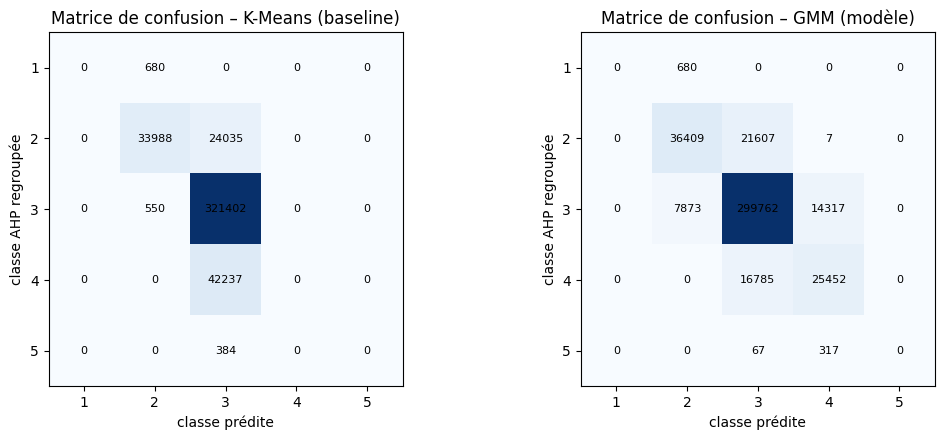

Meilleur F1 macro : GMM (modèle) | Plus faible RMSE : K-Means (baseline)
ARI K-Means vs GMM (test) : 0.2895


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, cm, t in zip(ax, [cm_km, cm_gm], ["K-Means (baseline)", "GMM (modèle)"]):
    a.imshow(cm, cmap="Blues"); a.set_title(f"Matrice de confusion – {t}")
    a.set_xticks(range(len(CLASSES))); a.set_xticklabels(CLASSES); a.set_yticks(range(len(CLASSES))); a.set_yticklabels(CLASSES)
    a.set_xlabel("classe prédite"); a.set_ylabel("classe AHP regroupée")
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "matrices_confusion.png", dpi=150); plt.show()

meilleur_f1 = comparaison["f1_macro"].drop("Référence naïve (classe majoritaire)").idxmax()
meilleur_rmse = comparaison["rmse_score"].drop("Référence naïve (classe majoritaire)").idxmin()
print(f"Meilleur F1 macro : {meilleur_f1} | Plus faible RMSE : {meilleur_rmse}")
print("ARI K-Means vs GMM (test) :", round(adjusted_rand_score(pred_test[1], pred_test[2]), 4))

## 6. `ClusterTypologie` (`calculerPriorite()`) et `AffectationCluster` sur toutes les mailles

In [16]:
# Prédiction des deux modèles (entraînés sur le train) pour toutes les mailles valides
resultats = {m.id: m.predire(X) for m in modeles}

LIBELLES = {1: "très élevé", 2: "élevé", 3: "modéré", 4: "faible", 5: "très faible"}
INTERVENTIONS = {
    "hydro": "Aménagement hydraulique : curage, bassins de rétention, renforcement du drainage",
    "sol":   "Gestion des eaux pluviales : désimperméabilisation, noues, revêtements perméables",
    "oued":  "Protection des berges et zones tampons le long des oueds",
    "bati":  "Maîtrise de l'urbanisation exposée et adaptation du bâti et de la voirie",
    "secours": "Renforcement de l'accès aux secours et des équipements",
}
FAMILLE = {"hand_moy": "hydro", "twi_moy": "hydro", "flux_max_log": "hydro", "depression_moy": "hydro",
           "pente_moy": "hydro", "pct_impermeable": "sol", "ruissel_moy": "sol", "distance_oued": "oued",
           "densite_bati": "bati", "densite_routes": "bati",
           "distance_secours": "secours", "indice_equip": "secours"}

LIBELLES_K = {3: ["élevé", "modéré", "faible"],
              4: ["très élevé", "élevé", "modéré", "faible"],
              5: ["très élevé", "élevé", "modéré", "faible", "très faible"]}

def libelle_rang(p, k):
    """p = 1 (plus urgent) … k."""
    return LIBELLES_K[k][p - 1] if k in LIBELLES_K else f"priorité {p}/{k}"

def calculer_priorite(modele, groupes):
    """profil_moyen, ahp_moyen, priorite (1 = plus urgent), libelle et intervention d'après le profil."""
    g = pd.Series(groupes)
    profil = V.groupby(g).mean()
    ahp = valeur.groupby(g).mean()
    prio = ahp.rank(ascending=False, method="first").astype(int)
    z = (profil - V.mean()) / V.std().replace(0, 1)

    lignes = []
    for k in profil.index:
        dominante = z.loc[k].idxmax()
        p = int(prio[k])
        lignes.append({
            "id": (modele.id - 1) * modele.n_clusters + int(k) + 1,
            "modele_id": modele.id, "groupe": int(k),
            "libelle": f"Risque {libelle_rang(p, modele.n_clusters)} – dominante {dominante}",
            "profil_moyen": json.dumps(profil.loc[k].round(4).to_dict(), ensure_ascii=False),
            "ahp_moyen": float(ahp[k]), "priorite": p,
            "intervention": INTERVENTIONS[FAMILLE[dominante]] if p < modele.n_clusters
                            else "Surveillance et entretien courant"})
    return pd.DataFrame(lignes)

typologie = pd.concat([calculer_priorite(m, resultats[m.id][0]) for m in modeles], ignore_index=True)
typologie.drop(columns="groupe").to_csv(OUT / "cluster_typologie.csv", index=False)

parts = []
for m in modeles:
    groupes, proba = resultats[m.id]
    table = typologie.query("modele_id == @m.id").set_index("groupe")["id"]
    parts.append(pd.DataFrame({"maille_id": maille_id, "modele_id": m.id,
                               "cluster_id": pd.Series(groupes).map(table).to_numpy(),
                               "probabilite": proba}))
affectation = pd.concat(parts, ignore_index=True)
affectation.to_csv(OUT / "affectation_cluster.csv", index=False)

print(affectation.groupby(["modele_id", "cluster_id"]).size().unstack(0))
typologie.drop(columns=["profil_moyen", "groupe"])

modele_id          1          2
cluster_id                     
1           433431.0        NaN
2           704020.0        NaN
3           381888.0        NaN
4           314296.0        NaN
5           187070.0        NaN
6                NaN  1000603.0
7                NaN   199546.0
8                NaN   234688.0
9                NaN    45726.0
10               NaN   540142.0


,id,modele_id,libelle,ahp_moyen,priorite,intervention
0,1,1,Risque élevé – dominante distance_oued,0.410147,2,Protection des berges et zones tampons le long...
1,2,1,Risque faible – dominante ruissel_moy,0.347531,4,Gestion des eaux pluviales : désimperméabilisa...
2,3,1,Risque modéré – dominante distance_secours,0.361047,3,Renforcement de l'accès aux secours et des équ...
3,4,1,Risque très élevé – dominante flux_max_log,0.435564,1,"Aménagement hydraulique : curage, bassins de r..."
4,5,1,Risque très faible – dominante indice_equip,0.265134,5,Surveillance et entretien courant
5,6,2,Risque modéré – dominante distance_oued,0.371080,3,Protection des berges et zones tampons le long...
6,7,2,Risque très élevé – dominante twi_moy,0.458977,1,"Aménagement hydraulique : curage, bassins de r..."
7,8,2,Risque très faible – dominante indice_equip,0.277399,5,Surveillance et entretien courant
8,9,2,Risque élevé – dominante pct_impermeable,0.418219,2,Gestion des eaux pluviales : désimperméabilisa...
9,10,2,Risque faible – dominante distance_secours,0.369711,4,Renforcement de l'accès aux secours et des équ...


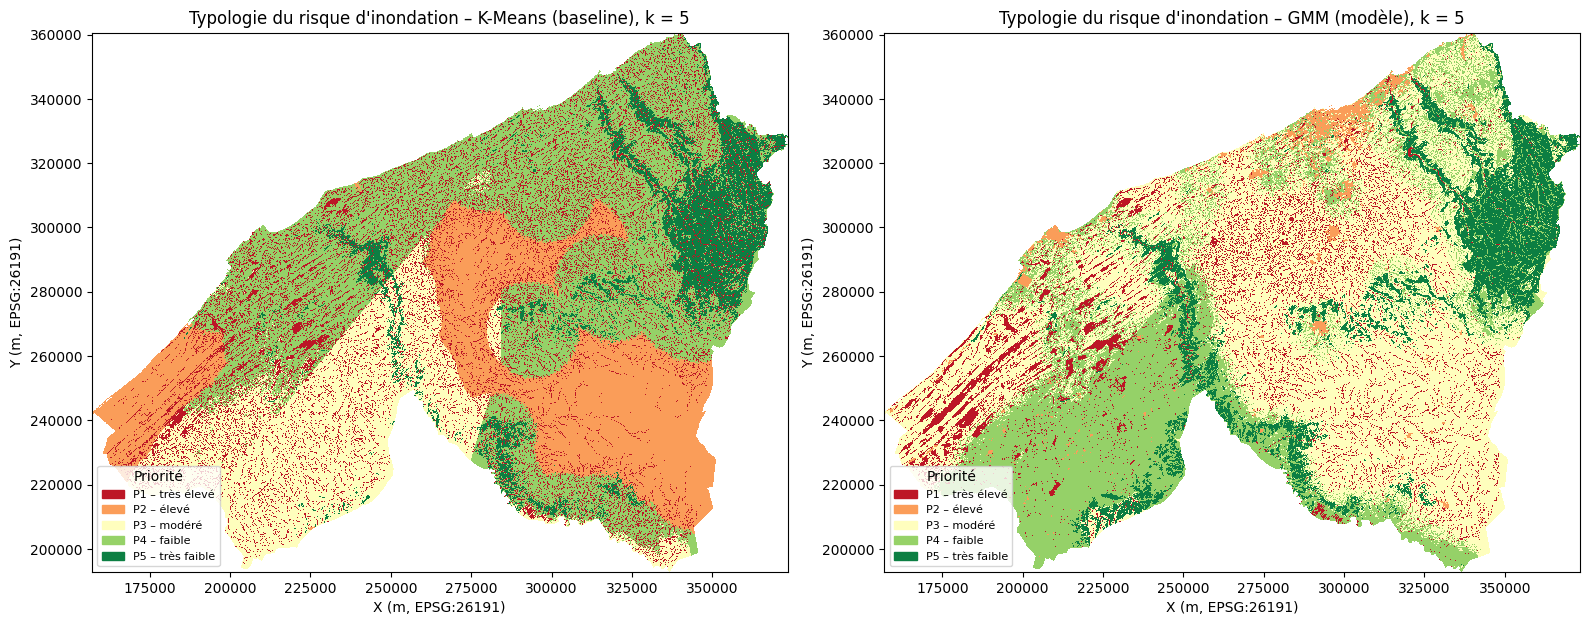

In [17]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

PAS = 100                                            # taille de la maille (m)
x, y = sub["centroide_x"].to_numpy(), sub["centroide_y"].to_numpy()
ix, iy = ((x - x.min()) // PAS).astype(int), ((y - y.min()) // PAS).astype(int)
extent = [x.min() - PAS / 2, x.max() + PAS / 2, y.min() - PAS / 2, y.max() + PAS / 2]

def carte_priorite(ax, modele, titre):
    k = modele.n_clusters
    prio_par_g = typologie.query("modele_id == @modele.id").set_index("groupe")["priorite"]
    prio = pd.Series(resultats[modele.id][0]).map(prio_par_g).to_numpy()
    grille = np.full((iy.max() + 1, ix.max() + 1), np.nan)
    grille[iy, ix] = prio                            # 1 = plus urgent
    couleurs = plt.cm.RdYlGn(np.linspace(0.05, 0.95, k))          # rouge (urgent) -> vert (faible)
    ax.imshow(grille, origin="lower", extent=extent, interpolation="nearest",
              cmap=ListedColormap(couleurs), norm=BoundaryNorm(np.arange(0.5, k + 1.5), k))
    ax.legend(handles=[Patch(color=couleurs[p - 1], label=f"P{p} – {libelle_rang(p, k)}") for p in range(1, k + 1)],
              loc="lower left", fontsize=8, title="Priorité")
    ax.set_title(titre); ax.set_aspect("equal")
    ax.set_xlabel("X (m, EPSG:26191)"); ax.set_ylabel("Y (m, EPSG:26191)")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, m, t in zip(ax, modeles, ["K-Means (baseline)", "GMM (modèle)"]):
    carte_priorite(a, m, f"Typologie du risque d'inondation – {t}, k = {m.n_clusters}")
plt.tight_layout(); plt.savefig(OUT / "carte_clusters.png", dpi=200); plt.show()


### Aléa et vulnérabilité séparés
`score_alea` (hydro, sol, oued) et `score_vulnerabilite` (bâti, routes, secours), pondérés par les poids AHP.

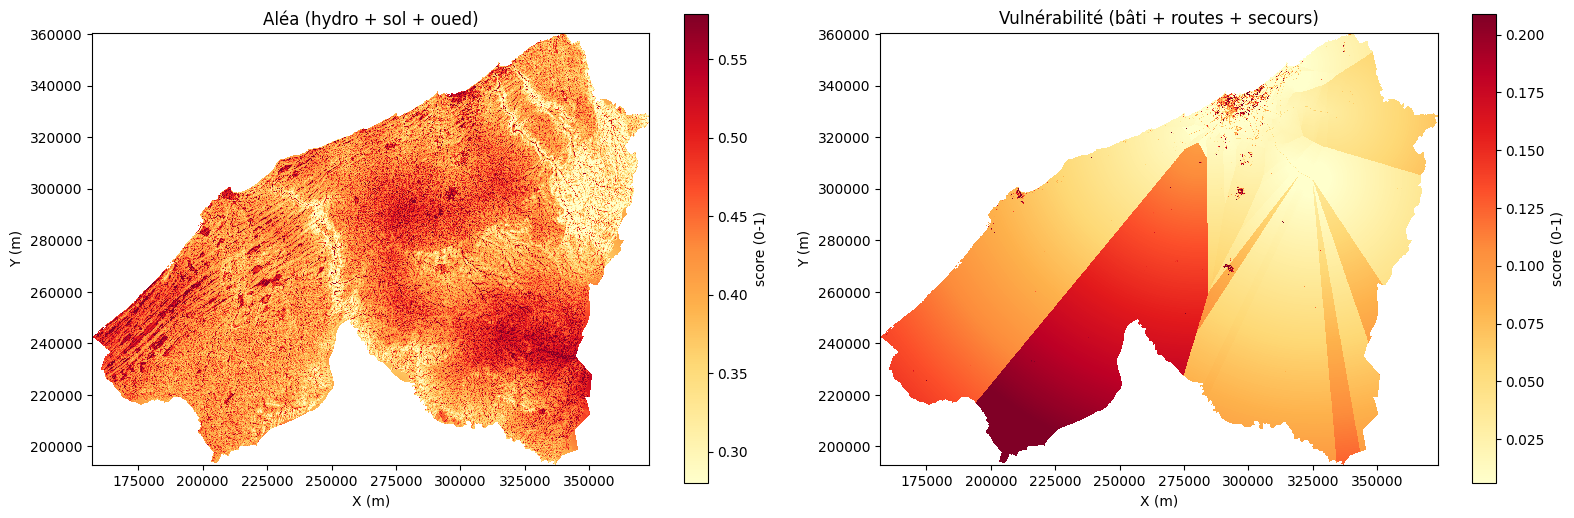

alea          vulnerabilite         
           mean    count          mean    count
priorite                                       
1         0.534   199546         0.083   199546
2         0.486    45726         0.080    45726
3         0.432  1000603         0.067  1000603
4         0.420   540142         0.120   540142
5         0.320   234688         0.066   234688

In [18]:
# Aléa et vulnérabilité cartographiés séparément
ALEA = ["hand_moy", "twi_moy", "flux_max_log", "depression_moy", "pente_moy",
        "pct_impermeable", "ruissel_moy", "distance_oued"]
VULN = ["densite_bati", "densite_routes", "distance_secours", "indice_equip"]
manquantes = [c for c in ALEA + VULN if c not in criteres]
assert not manquantes, f"Variables absentes de critere_ahp : {manquantes}"

def score_groupe(cols):
    w = poids[cols].to_numpy(dtype="float32")
    return (V[cols].to_numpy() * w).sum(axis=1) / w.sum()      # V déjà orienté (1 = plus défavorable)

score_alea = score_groupe(ALEA)
score_vulnerabilite = score_groupe(VULN)

def carte_score(ax, s, titre):
    grille = np.full((iy.max() + 1, ix.max() + 1), np.nan, dtype="float32")
    grille[iy, ix] = s
    im = ax.imshow(grille, origin="lower", extent=extent, interpolation="nearest", cmap="YlOrRd",
                   vmin=np.nanpercentile(s, 2), vmax=np.nanpercentile(s, 98))
    plt.colorbar(im, ax=ax, shrink=.7, label="score (0-1)")
    ax.set_title(titre); ax.set_aspect("equal"); ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
carte_score(ax[0], score_alea, "Aléa (hydro + sol + oued)")
carte_score(ax[1], score_vulnerabilite, "Vulnérabilité (bâti + routes + secours)")
plt.tight_layout(); plt.savefig(OUT / "carte_alea_vulnerabilite.png", dpi=200); plt.show()

# Contrôle : profil aléa / vulnérabilité de chaque priorité GMM (P1 rural = aléa fort, vulnérabilité faible ?)
prio_g = typologie.query("modele_id == 2").set_index("groupe")["priorite"]
prio_gmm = pd.Series(resultats[2][0]).map(prio_g).to_numpy()
display(pd.DataFrame({"priorite": prio_gmm, "alea": score_alea, "vulnerabilite": score_vulnerabilite})
        .groupby("priorite").agg(["mean", "count"]).round(3))

In [19]:
from scipy.spatial import cKDTree

SEUIL_ELEVE = 2          # zone « élevée » = priorité <= 2 (P1 + P2)

# Centres approximatifs (EPSG:26191, X, Y) de lieux cités comme exposés aux inondations (presse, SRM/Lydec, études)
LIEUX = {"Aïn Sebaâ": (302255, 336400), "Sidi Bernoussi": (306424, 336039), "Sidi Moumen": (304999, 334404),
         "Aïn Chock": (298389, 328994), "Mohammedia": (316057, 344900), "Lahraouyine": (309906, 324326),
         "Bouskoura": (290763, 319019), "Sidi Maârouf": (290011, 328063), "Nouaceur": (296753, 309810),
         "Berrechid": (296127, 298578), "Settat": (292795, 269351), "El Jadida": (210989, 296999),
         "Benslimane": (340376, 336651)}
RAYON = 2000                                         # m autour du centre

arbre = cKDTree(np.c_[x, y])                         # x, y définis dans la cellule de la carte
prio_g = typologie.query("modele_id == 2").set_index("groupe")["priorite"]   # GMM
prio = pd.Series(resultats[2][0]).map(prio_g).to_numpy()

lignes = []
for nom, (px, py) in LIEUX.items():
    idx = arbre.query_ball_point([px, py], RAYON)
    if not idx:
        lignes.append({"lieu": nom, "n_mailles": 0}); continue
    p = prio[idx]
    lignes.append({"lieu": nom, "n_mailles": len(idx),
                   "pct_P1": 100 * (p == 1).mean(),
                   f"pct_P1_P{SEUIL_ELEVE}": 100 * (p <= SEUIL_ELEVE).mean(),
                   "priorite_mediane": float(np.median(p))})
pd.DataFrame(lignes).set_index("lieu").round(1)

,n_mailles,pct_P1,pct_P1_P2,priorite_mediane
lieu,,,,
Aïn Sebaâ,1203,1.2,89.4,2.0
Sidi Bernoussi,1258,0.6,78.6,2.0
Sidi Moumen,1266,5.9,67.5,2.0
Aïn Chock,1262,7.2,55.5,2.0
Mohammedia,1254,4.5,79.8,2.0
Lahraouyine,1256,9.6,11.6,3.0
Bouskoura,1257,7.5,37.5,3.0
Sidi Maârouf,1257,5.8,56.3,2.0
Nouaceur,1251,11.6,27.8,4.0


## 6 bis. Intersection mailles × communes → `Commune` et `PrioriteCommune`
Chaque maille est rattachée à **une seule commune** par son centroïde (intersection point-polygone), ce qui évite de compter deux fois une maille à cheval sur une limite.
Pour chaque maille on récupère la priorité du GMM (P1 = plus urgent), son cluster et son score AHP. La couche des communes est lue en EPSG:26191.

In [20]:
import geopandas as gpd
from shapely.geometry import MultiPolygon

GPKG_COMMUNES = ROOT / "donnees_traitees" / "casablanca_settat_clean" / "communes_casablanca_settat_clean.gpkg"
MODELE_ID = 2            # GMM (modèle retenu)
SEUIL_ELEVE = 2          # zone « élevée » = priorité <= 2 (P1 + P2)
COL_BATI_M2 = None       # colonne de sub donnant le bâti en m² par maille, si elle existe (sinon None)

# --- 1. Communes : champs id, nom, osm_id, surface_km2 (EPSG:26191, MultiPolygon)
communes = gpd.read_file(GPKG_COMMUNES).to_crs(26191).reset_index(drop=True)
assert communes["id"].is_unique, "id des communes non unique"
communes["code_commune"] = communes["osm_id"].astype(str).str.replace(r"\.0$", "", regex=True)   # osm_id = code de la commune
communes["geometry"] = communes.geometry.apply(lambda g: g if g.geom_type == "MultiPolygon" else MultiPolygon([g]))
print(f"{len(communes)} communes | colonnes : {[c for c in communes.columns if c != 'geometry']}")

# --- 2. Mailles : centroïdes + cluster, priorité et score AHP du modèle retenu
tab = typologie.query("modele_id == @MODELE_ID").set_index("groupe")
g_mailles = pd.Series(resultats[MODELE_ID][0])
pts = gpd.GeoDataFrame({"maille_id": sub["id"].to_numpy(),
                        "cluster_id": g_mailles.map(tab["id"]).to_numpy(),
                        "priorite": g_mailles.map(tab["priorite"]).to_numpy(),
                        "score": valeur.to_numpy(),
                        "bati_m2": sub[COL_BATI_M2].to_numpy() if COL_BATI_M2 else np.nan},
                       geometry=gpd.points_from_xy(sub["centroide_x"], sub["centroide_y"]), crs=26191)

# --- 3. Intersection mailles x communes (une maille = une seule commune)
j = gpd.sjoin(pts, communes[["geometry"]], how="left", predicate="intersects").drop_duplicates("maille_id")
print(f"Mailles sans commune : {j['index_right'].isna().sum():,} sur {len(j):,}")
j = j.dropna(subset=["index_right"]).copy()
j["commune_id"] = j["index_right"].astype(int).map(communes["id"])

153 communes | colonnes : ['id', 'osm_id', 'nom', 'surface_km2', 'code_commune']
Mailles sans commune : 0 sur 2,020,705


### Agrégation par commune (`agregerScores()` / `calculerPriorite()`)
- `pct_zones_elevees` : part des mailles en P1 + P2 ; `score_moyen` / `score_max` : score AHP des mailles ; `bati_expose_m2` : bâti situé dans les mailles P1 + P2 (si la colonne existe) ;
- `cluster_dominant_id` : cluster le plus fréquent dans la commune ;
- `indice_priorite` : combinaison pondérée de composantes normalisées 0-1 (pourcentage de zones élevées, score moyen, bâti exposé) ; **les poids sont à justifier** ;
- `couverture_pct` (contrôle) : surface couverte par les mailles / `surface_km2` de la commune ;
- `rang_priorite` : 1 = commune la plus urgente ; `recommandation` : niveau (top 10 % très prioritaire, 30 % prioritaire) + intervention du cluster dominant.

In [21]:
POIDS = {"pct_zones_elevees": 0.45, "score_moyen": 0.35, "bati_expose_m2": 0.20}   # à ajuster / justifier

j["elevee"] = j["priorite"] <= SEUIL_ELEVE
j["bati_exp"] = np.where(j["elevee"], j["bati_m2"], 0.0)
g = j.groupby("commune_id")

pc = pd.DataFrame({
    "n_mailles": g.size(),
    "cluster_dominant_id": g["cluster_id"].agg(lambda s: int(s.mode().iloc[0])),     # cluster le plus fréquent
    "pct_zones_elevees": 100 * g["elevee"].mean(),
    "score_moyen": g["score"].mean(),
    "score_max": g["score"].max(),
    "bati_expose_m2": g["bati_exp"].sum() if COL_BATI_M2 else np.nan})
# contrôle : surface couverte par les mailles (100 m x 100 m = 0,01 km²) / surface de la commune
pc["couverture_pct"] = 100 * pc["n_mailles"] * 0.01 / communes.set_index("id")["surface_km2"].reindex(pc.index)

# --- indice de priorité : composantes normalisées (0-1) pondérées ; composantes absentes ignorées
def mm(s):
    return (s - s.min()) / (s.max() - s.min()) if s.notna().any() and s.max() > s.min() else s * 0
comp = pd.DataFrame({"pct_zones_elevees": mm(pc["pct_zones_elevees"]), "score_moyen": mm(pc["score_moyen"]),
                     "bati_expose_m2": mm(pc["bati_expose_m2"])})
w = pd.Series(POIDS)[comp.columns[comp.notna().any()]]
w = w / w.sum()
print("Poids effectifs :", w.round(3).to_dict())
pc["indice_priorite"] = (comp[w.index] * w).sum(axis=1)

# --- rang et recommandation
pc["rang_priorite"] = pc["indice_priorite"].rank(ascending=False, method="first").astype(int)
niveau = pd.cut(pc["rang_priorite"] / len(pc), [0, .10, .30, 1], labels=["Très prioritaire", "Prioritaire", "Suivi"])
interv = typologie.query("modele_id == @MODELE_ID").set_index("id")["intervention"]
pc["recommandation"] = niveau.astype(str) + " : " + pc["cluster_dominant_id"].map(interv)

priorite_commune = (pc.reset_index().assign(calcul_id=CALCUL_ID)
                    [["commune_id", "calcul_id", "cluster_dominant_id", "pct_zones_elevees", "score_moyen",
                      "score_max", "bati_expose_m2", "indice_priorite", "rang_priorite", "recommandation"]]
                    .sort_values("rang_priorite"))

apercu = pc.join(communes.set_index("id")["nom"]).sort_values("rang_priorite")
apercu[["nom", "n_mailles", "couverture_pct", "pct_zones_elevees", "score_moyen",
        "indice_priorite", "rang_priorite", "recommandation"]].head(15).round(2)

Poids effectifs : {'pct_zones_elevees': 0.562, 'score_moyen': 0.437}


,nom,n_mailles,couverture_pct,pct_zones_elevees,score_moyen,indice_priorite,rang_priorite,recommandation
commune_id,,,,,,,,
33,El Jadida ⵍⵊⴰⴷⵉⴷⴰ الجديدة,2993,100.07,80.35,0.43,0.93,1,Très prioritaire : Gestion des eaux pluviales ...
10,Berrechid برشيد,3017,99.90,58.44,0.43,0.77,2,Très prioritaire : Gestion des eaux pluviales ...
76,Mohammédia المحمدية,3506,100.20,69.17,0.38,0.74,3,Très prioritaire : Gestion des eaux pluviales ...
83,Médiouna مديونة,439,99.77,59.00,0.40,0.72,4,Très prioritaire : Gestion des eaux pluviales ...
23,Casablanca ⵜⴰⴷⴷⴰⵔⵜ ⵜⵓⵎⵍⵉⵍⵜ الدار البيضاء,21606,100.01,63.89,0.38,0.68,5,Très prioritaire : Gestion des eaux pluviales ...
40,Had Soualem حـد الـسـوالـم,1915,99.84,55.93,0.39,0.67,6,Très prioritaire : Gestion des eaux pluviales ...
2,Azemmour أزمور,448,100.90,62.50,0.37,0.67,7,Très prioritaire : Gestion des eaux pluviales ...
30,Deroua ⴷⵔⵡⴰ الدروة,1376,100.07,53.71,0.40,0.66,8,Très prioritaire : Gestion des eaux pluviales ...
57,Lahraouyine الهراويين,1642,99.82,54.69,0.39,0.65,9,Très prioritaire : Protection des berges et zo...


### Export des tables `Commune` et `PrioriteCommune` + carte
CSV pour la base PostGIS, GeoPackage pour QGIS.

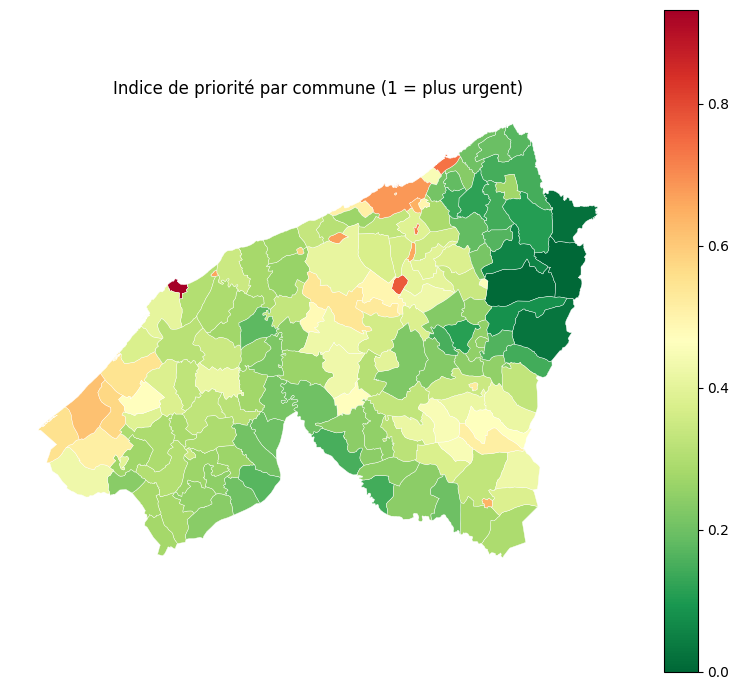

In [22]:
commune = communes[["id", "code_commune", "nom", "surface_km2", "geometry"]]
commune.drop(columns="geometry").to_csv(OUT / "commune.csv", index=False)
priorite_commune.to_csv(OUT / "priorite_commune.csv", index=False)
commune.to_file(OUT / "commune.gpkg", layer="commune", driver="GPKG")                       # géométrie MultiPolygon [26191]
carte = commune.merge(priorite_commune, left_on="id", right_on="commune_id", how="left")
carte.to_file(OUT / "priorite_commune.gpkg", layer="priorite_commune", driver="GPKG")       # à ouvrir dans QGIS

fig, ax = plt.subplots(figsize=(8, 7))
carte.plot(column="indice_priorite", cmap="RdYlGn_r", legend=True, edgecolor="white", linewidth=.3,
           ax=ax, missing_kwds={"color": "lightgrey"})
ax.set_title("Indice de priorité par commune (1 = plus urgent)"); ax.set_axis_off()
plt.tight_layout(); plt.savefig(OUT / "carte_priorite_commune.png", dpi=200); plt.show()

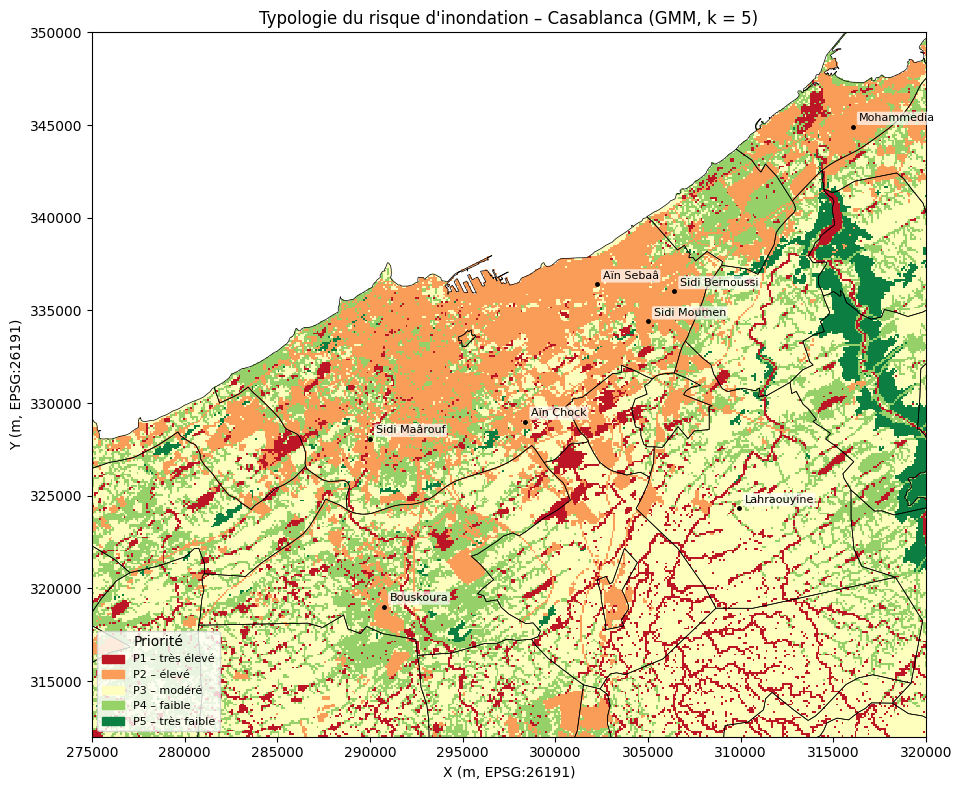

In [23]:
BBOX_CASA = (275000, 320000, 312000, 350000)         # xmin, xmax, ymin, ymax (EPSG:26191) : à ajuster si besoin
MODELE_CARTE = modeles[1]                            # GMM

fig, ax = plt.subplots(figsize=(10, 8))
carte_priorite(ax, MODELE_CARTE, f"Typologie du risque d'inondation – Casablanca (GMM, k = {MODELE_CARTE.n_clusters})")
communes.boundary.plot(ax=ax, color="k", linewidth=0.5)                          # limites communales
for nom, (px, py) in LIEUX.items():                                              # repères (cellule de vérification)
    if BBOX_CASA[0] < px < BBOX_CASA[1] and BBOX_CASA[2] < py < BBOX_CASA[3]:
        ax.plot(px, py, "k.", ms=5)
        ax.annotate(nom, (px, py), xytext=(4, 4), textcoords="offset points", fontsize=8,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.7, lw=0))
ax.set_xlim(BBOX_CASA[0], BBOX_CASA[1]); ax.set_ylim(BBOX_CASA[2], BBOX_CASA[3])
plt.tight_layout(); plt.savefig(OUT / "carte_casablanca.png", dpi=200); plt.show()

### Résultats par maille sur Casablanca
Table des mailles de la zone `BBOX_CASA` : score et classe AHP, cluster et priorité K-Means, cluster, priorité, libellé et probabilité du GMM. Export CSV et GeoPackage (carrés de 100 m) pour QGIS.

In [24]:
from shapely.geometry import box

MOTIF_COMMUNE = None       # ex. "Casablanca" pour ne garder que les mailles de cette commune (sinon : toute la fenêtre BBOX_CASA)
AVEC_VARIABLES = False     # True : ajoute les 12 variables (orientées risque) à chaque maille

def info(modele):
    tab = typologie.query("modele_id == @modele.id").set_index("groupe")
    g, p = resultats[modele.id]
    s = pd.Series(g)
    return s.map(tab["id"]).to_numpy(), s.map(tab["priorite"]).to_numpy(), s.map(tab["libelle"]).to_numpy(), p

cl_k, pr_k, _, _ = info(modeles[0])                          # K-Means
cl_g, pr_g, lib_g, proba_g = info(modeles[1])                # GMM

res_maille = pd.DataFrame({
    "maille_id": sub["id"], "x": sub["centroide_x"], "y": sub["centroide_y"],
    "commune": j["commune_id"].map(communes.set_index("id")["nom"]).reindex(sub.index),
    "score_ahp": valeur.to_numpy(), "classe_ahp": classe.to_numpy(),
    "kmeans_cluster_id": cl_k, "kmeans_priorite": pr_k,
    "gmm_cluster_id": cl_g, "gmm_priorite": pr_g, "gmm_libelle": lib_g, "gmm_probabilite": proba_g})
if AVEC_VARIABLES:
    res_maille = res_maille.join(V)

masque = (res_maille["x"].between(BBOX_CASA[0], BBOX_CASA[1]) & res_maille["y"].between(BBOX_CASA[2], BBOX_CASA[3]))
if MOTIF_COMMUNE:
    masque &= res_maille["commune"].str.contains(MOTIF_COMMUNE, case=False, na=False)
res_casa = res_maille[masque].reset_index(drop=True)
print(f"{len(res_casa):,} mailles sur la zone de Casablanca")

# --- synthèse par priorité (GMM)
synthese = (res_casa.groupby(["gmm_priorite", "gmm_libelle"])
            .agg(n_mailles=("maille_id", "size"), score_ahp_moyen=("score_ahp", "mean"),
                 proba_moyenne=("gmm_probabilite", "mean")).reset_index())
synthese["pct_mailles"] = 100 * synthese["n_mailles"] / synthese["n_mailles"].sum()
print(synthese.round(3).to_string(index=False))

# --- export : CSV + GeoPackage (carrés de 100 m) pour QGIS
res_casa.to_csv(OUT / "resultats_mailles_casablanca.csv", index=False)
carres = [box(px - 50, py - 50, px + 50, py + 50) for px, py in zip(res_casa["x"], res_casa["y"])]
gpd.GeoDataFrame(res_casa, geometry=carres, crs=26191).to_file(
    OUT / "resultats_mailles_casablanca.gpkg", layer="mailles", driver="GPKG")
res_casa.head(10).round(3)

117,391 mailles sur la zone de Casablanca
 gmm_priorite                                 gmm_libelle  n_mailles  score_ahp_moyen  proba_moyenne  pct_mailles
            1       Risque très élevé – dominante twi_moy      10083            0.434          0.886        8.589
            2    Risque élevé – dominante pct_impermeable      23681            0.403          0.990       20.173
            3     Risque modéré – dominante distance_oued      52072            0.338          0.785       44.358
            4  Risque faible – dominante distance_secours      27251            0.357          0.700       23.214
            5 Risque très faible – dominante indice_equip       4304            0.273          0.889        3.666


,maille_id,x,y,commune,score_ahp,classe_ahp,kmeans_cluster_id,kmeans_priorite,gmm_cluster_id,gmm_priorite,gmm_libelle,gmm_probabilite
0,1706581,275050.0,312050.0,Sahel Oulad H'riz الساحل أولاد حريز,0.380,3,2,4,7,1,Risque très élevé – dominante twi_moy,0.926
1,1706582,275150.0,312050.0,Sahel Oulad H'riz الساحل أولاد حريز,0.460,4,4,1,7,1,Risque très élevé – dominante twi_moy,1.000
2,1706583,275250.0,312050.0,Sahel Oulad H'riz الساحل أولاد حريز,0.469,4,4,1,7,1,Risque très élevé – dominante twi_moy,1.000
3,1706584,275350.0,312050.0,Sahel Oulad H'riz الساحل أولاد حريز,0.439,3,4,1,7,1,Risque très élevé – dominante twi_moy,1.000
4,1706585,275450.0,312050.0,Sahel Oulad H'riz الساحل أولاد حريز,0.551,4,4,1,7,1,Risque très élevé – dominante twi_moy,1.000
5,1706586,275550.0,312050.0,Sahel Oulad H'riz الساحل أولاد حريز,0.388,3,2,4,7,1,Risque très élevé – dominante twi_moy,0.968
6,1706587,275650.0,312050.0,Sahel Oulad H'riz الساحل أولاد حريز,0.335,3,2,4,6,3,Risque modéré – dominante distance_oued,0.772
7,1706588,275750.0,312050.0,Sahel Oulad H'riz الساحل أولاد حريز,0.365,3,2,4,6,3,Risque modéré – dominante distance_oued,0.725
8,1706589,275850.0,312050.0,Sahel Oulad H'riz الساحل أولاد حريز,0.353,3,2,4,6,3,Risque modéré – dominante distance_oued,0.745
9,1706590,275950.0,312050.0,Sahel Oulad H'riz الساحل أولاد حريز,0.366,3,2,4,6,3,Risque modéré – dominante distance_oued,0.702


## 7. Documentation des choix de modélisation

In [25]:
doc = {
    "algorithmes": {"baseline": "K-Means (n_init=10, init k-means++)",
                    "modele": f"GMM covariance '{COV_CHOISIE}', n_init=3, k={K_CHOISI}"},
    "entrees": "variables normalisées (orientées risque) × √poids AHP",
    "k": {"teste": [min(K_RANGE), max(K_RANGE)], "candidats": K_CAND, "votes": votes, "retenu": K_CHOISI,
          "validation": f"CV spatiale {N_FOLDS} plis sur le train"},
    "decoupage": mode_split, "test_frac": TEST_FRAC, "graine": SEED,
    "metriques_internes": ["silhouette", "davies_bouldin", "calinski_harabasz", "BIC / loglik (GMM)"],
    "metriques_supervisees": ["accuracy", "précision/rappel/F1 macro", "matrice de confusion", "RMSE score"],
    "references": ["K-Means (baseline du GMM)", "classe majoritaire / score moyen (référence naïve)"],
}
(OUT / "documentation_modeles.json").write_text(json.dumps(doc, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(json.dumps(doc, ensure_ascii=False, indent=2, default=str))

{
  "algorithmes": {
    "baseline": "K-Means (n_init=10, init k-means++)",
    "modele": "GMM covariance 'full', n_init=3, k=5"
  },
  "entrees": "variables normalisées (orientées risque) × √poids AHP",
  "k": {
    "teste": [
      2,
      10
    ],
    "candidats": [
      3,
      4,
      5,
      6,
      7,
      8
    ],
    "votes": {
      "coude_icl": 5,
      "coude_loglik_val": 5,
      "coude_eta2_ahp": 5
    },
    "retenu": 5,
    "validation": "CV spatiale 3 plis sur le train"
  },
  "decoupage": "spatial (blocs de 5000 m)",
  "test_frac": 0.2,
  "graine": 42,
  "metriques_internes": [
    "silhouette",
    "davies_bouldin",
    "calinski_harabasz",
    "BIC / loglik (GMM)"
  ],
  "metriques_supervisees": [
    "accuracy",
    "précision/rappel/F1 macro",
    "matrice de confusion",
    "RMSE score"
  ],
  "references": [
    "K-Means (baseline du GMM)",
    "classe majoritaire / score moyen (référence naïve)"
  ]
}


In [26]:
pip install geoalchemy2

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# ==============================================================================
# EXPORT POSTGIS : couche dérivée (EPSG:26191) + métadonnées de traçabilité
# Cellule à placer à la FIN du notebook, après la création de res_casa / carres
# ==============================================================================
import os
from datetime import datetime
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import geopandas as gpd
from sqlalchemy import create_engine, text

# --- 1. Connexion à la base geoai_casablanca ----------------------------------
DB_USER = "postgres"
DB_PASS = "PASSEWORD"          # mot de passe lu dans la variable d'environnement
DB_HOST, DB_PORT, DB_NAME = "localhost", "5432", "geoai_casablanca"
engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{quote_plus(DB_PASS)}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

CRS_EPSG = 26191                             # Merchich / Nord Maroc
T_META   = "clustering_metadonnees_tracabilite"
T_COUCHE = "couche_inondation_derivee_mailles"
DATE_TRAITEMENT = datetime.now()

# --- 2. Préparation PostGIS : extension + contrôle du CRS ---------------------
with engine.begin() as conn:
    conn.execute(text("CREATE EXTENSION IF NOT EXISTS postgis"))
    version = conn.execute(text("SELECT PostGIS_Version()")).scalar()
    n_srid = conn.execute(text("SELECT COUNT(*) FROM spatial_ref_sys WHERE srid = :s"),
                          {"s": CRS_EPSG}).scalar()
assert n_srid == 1, f"EPSG:{CRS_EPSG} absent de spatial_ref_sys"
print(f"[OK] PostGIS {version} actif, EPSG:{CRS_EPSG} disponible")

# --- 3. Table de métadonnées : modèle utilisé + date + métriques du TEST ------
meta = modele_clustering.copy()              # id, calcul_id, role, type, n_clusters, date_entrainement,
                                             # silhouette, davies_bouldin, calinski_harabasz, covariance, bic, ...
meta["modele_nom"] = meta["type"].map({"KMeans": "K-Means (baseline)", "GMM": "GMM (modèle)"})

metriques = (comparaison.reset_index().rename(columns={"modele": "modele_nom"})
             [["modele_nom", "accuracy", "precision_macro", "rappel_macro", "f1_macro", "rmse_score"]])
meta = meta.merge(metriques, on="modele_nom", how="left").drop(columns="modele_nom")

meta["date_entrainement"] = pd.to_datetime(meta["date_entrainement"])
meta["date_traitement"]   = pd.Timestamp(DATE_TRAITEMENT)
meta["modele_retenu"]     = meta["id"].eq(MODELE_ID)
meta["k_choisi"]          = int(K_CHOISI)
meta["covariance_gmm"]    = str(COV_CHOISIE)
meta["graine"]            = int(SEED)
meta["bloc_m"]            = int(BLOC_M)
meta["part_test"]         = float(TEST_FRAC)
meta["nb_mailles_train"]  = int((~np.asarray(est_test)).sum())
meta["nb_mailles_test"]   = int(np.asarray(est_test).sum())
meta["crs_epsg"]          = CRS_EPSG

assert meta[["accuracy", "f1_macro", "rmse_score"]].notna().all().all(), "Métriques manquantes"

# --- 4. Couche spatiale dérivée (carrés de 100 m) avec CRS cohérent -----------
gdf = gpd.GeoDataFrame(
    res_casa.assign(calcul_id=CALCUL_ID, modele_retenu_id=MODELE_ID,
                    date_traitement=pd.Timestamp(DATE_TRAITEMENT)),
    geometry=carres,
    crs=f"EPSG:{CRS_EPSG}",
)
assert len(gdf) == len(res_casa) and gdf["maille_id"].is_unique
assert gdf.crs.to_epsg() == CRS_EPSG

# --- 5. Export (couche d'abord supprimée à cause de la clé étrangère) ---------
with engine.begin() as conn:
    conn.execute(text(f"DROP TABLE IF EXISTS {T_COUCHE} CASCADE"))
    conn.execute(text(f"DROP TABLE IF EXISTS {T_META} CASCADE"))

meta.to_sql(T_META, engine, if_exists="fail", index=False)
print(f"[OK] Table '{T_META}' : {len(meta)} lignes")

gdf.to_postgis(T_COUCHE, engine, if_exists="fail", index=False, chunksize=5000)
print(f"[OK] Couche '{T_COUCHE}' : {len(gdf):,} mailles (SRID {CRS_EPSG})")

# --- 6. Clés, lien de traçabilité et index spatial ----------------------------
with engine.begin() as conn:
    conn.execute(text(f"ALTER TABLE {T_META} ADD PRIMARY KEY (calcul_id, id)"))
    conn.execute(text(f"ALTER TABLE {T_COUCHE} ADD PRIMARY KEY (maille_id)"))
    conn.execute(text(f"""
        ALTER TABLE {T_COUCHE}
        ADD CONSTRAINT fk_couche_metadonnees
        FOREIGN KEY (calcul_id, modele_retenu_id) REFERENCES {T_META} (calcul_id, id)"""))
    a_gist = conn.execute(text(
        "SELECT COUNT(*) FROM pg_indexes WHERE tablename = :t AND indexdef ILIKE '%gist%'"),
        {"t": T_COUCHE}).scalar()
    if a_gist == 0:                          # to_postgis crée déjà l'index GiST dans la plupart des cas
        conn.execute(text(f"CREATE INDEX idx_{T_COUCHE}_geom ON {T_COUCHE} USING GIST (geometry)"))
with engine.connect().execution_options(isolation_level="AUTOCOMMIT") as conn:
    conn.execute(text(f"ANALYZE {T_COUCHE}"))
print("[OK] Clés primaires, clé étrangère, index spatial GiST, ANALYZE")

# --- 7. Vérifications ---------------------------------------------------------
with engine.connect() as conn:
    srid = conn.execute(text(f"SELECT Find_SRID('public', '{T_COUCHE}', 'geometry')")).scalar()
    n_lien = conn.execute(text(f"""
        SELECT COUNT(*) FROM {T_COUCHE} c
        JOIN {T_META} m ON c.calcul_id = m.calcul_id AND c.modele_retenu_id = m.id""")).scalar()
    n_invalides = conn.execute(text(
        f"SELECT COUNT(*) FROM {T_COUCHE} WHERE NOT ST_IsValid(geometry)")).scalar()
    trace = pd.read_sql(text(f"""
        SELECT m.id, m.type, m.role, m.n_clusters, m.date_entrainement, m.date_traitement,
               m.accuracy, m.f1_macro, m.rmse_score, m.silhouette
        FROM {T_META} m ORDER BY m.id"""), conn)

print(f"\nSRID détecté : {srid} (attendu {CRS_EPSG})")
print(f"{n_lien:,} mailles reliées à leur modèle ({len(gdf):,} attendues) | géométries invalides : {n_invalides}")
assert srid == CRS_EPSG and n_lien == len(gdf) and n_invalides == 0
trace.round(4)

[OK] PostGIS 3.5 USE_GEOS=1 USE_PROJ=1 USE_STATS=1 actif, EPSG:26191 disponible
[OK] Table 'clustering_metadonnees_tracabilite' : 2 lignes
[OK] Couche 'couche_inondation_derivee_mailles' : 117,391 mailles (SRID 26191)
[OK] Clés primaires, clé étrangère, index spatial GiST, ANALYZE

SRID détecté : 26191 (attendu 26191)
117,391 mailles reliées à leur modèle (117,391 attendues) | géométries invalides : 0


,id,type,role,n_clusters,date_entrainement,date_traitement,accuracy,f1_macro,rmse_score,silhouette
0,1,KMeans,baseline,5,2026-11-19 20:45:24,2026-11-19 20:50:31.029561,0.8396,0.3269,0.0340,0.2524
1,2,GMM,modele,5,2026-11-19 20:49:36,2026-11-19 20:50:31.029561,0.8543,0.4467,0.0404,0.1507


### Choix et limites
- **Pourquoi deux modèles** : K-Means (clusters sphériques, affectation dure) sert de baseline ; le GMM autorise des clusters de formes et de tailles différentes et donne une probabilité d'appartenance.
- **Pondération √poids** : elle pèse sur les distances de K-Means ; le GMM (covariances full/tied/diag) y est invariant, seule l'initialisation en dépend.
- **k** : choisi par validation croisée spatiale dans le train (coudes de l'ICL, de la log-vraisemblance et de η², filtres de stabilité et de taille) ; `K_MANUEL` permet d'imposer une valeur.
- **Circularité** : la classe AHP est une fonction linéaire des mêmes variables. F1 et RMSE mesurent donc dans quelle mesure les clusters retrouvent le score AHP, pas le risque réel. La validation externe (points noirs : taux de capture, AUC) reste à faire dans `Validation.valider()`.
- **Découpage** : un découpage aléatoire donne des scores trop optimistes (mailles voisines très corrélées). Les blocs spatiaux demandent des colonnes de coordonnées dans le CSV.
- **Autres limites** : GMM sensible à l'initialisation et aux variables très corrélées ; silhouette calculée sur un échantillon . Si k < 5, F1 et accuracy contre les 5 classes AHP sont plafonnés : privilégier RMSE et η².